In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np
%matplotlib inline

**This notebook analyzes singleton entries as a function of two input parameters to the Gestalt algorithm.**

param_1 and param_2 specify the names of the two parameters in question.
default_value variables specify a single value to be used when that parameter must be kept consistent for visualization.
output_folder is a path to the output folder generated by the parameter sweep code.

In [2]:
param_1 = 'Match proportion'
param_1_default_value = 0.8
param_2 = 'Trim quality'
param_2_default_value = 14
output_folder = 'output-data-extracted/OUTPUT_MP_TQ_extracted'

In [3]:
param_1 = 'Match proportion'
param_1_default_value = 0.8
param_2 = 'Match count'
param_2_default_value = 25
output_folder = 'output-data-extracted/OUTPUT_MP_MC_extracted'

In [4]:
param_1 = 'Trim quality'
param_1_default_value = 10
param_2 = 'Trim window'
param_2_default_value = 6
output_folder = 'output-data-extracted/OUTPUT_TQ_TW_extracted'

In [5]:
parameters_df = pd.read_csv(f'{output_folder}/parameters.csv').drop_duplicates().set_index('Directory name')
parameters_df.head()

,Match proportion,Match count,Trim quality,Trim window
Directory name,,,,
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,0.8,25,9,4
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW6-OUTPUT,0.8,25,9,6
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW8-OUTPUT,0.8,25,9,8
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW10-OUTPUT,0.8,25,9,10
Longitudinal_Sample6_MP0.8_MC25_TQ9_TW12-OUTPUT,0.8,25,9,12


In [6]:
output_dirs = []
for dir in parameters_df.index:
    output_dirs.append(dir)

In [7]:
allreadcounts_dfs = []
for dir in output_dirs:
    dirs = os.listdir(f'{output_folder}/{dir}')
    for i in range(len(dirs)):
        if not os.path.isdir(f'{output_folder}/{dir}/{dirs[i]}'):
            continue
        allreadcounts_dfs.append(pd.read_csv(f'{output_folder}/{dir}/{dirs[i]}/{dirs[i]}.allReadCounts', sep='\t'))
        allreadcounts_dfs[-1]['Directory name'] = dir
        allreadcounts_dfs[-1]['Fish'] = dirs[i]
allreadcounts_dfs[0].head()

,event,array,count,proportion,Directory name,Fish
0,57D+35_57D+35_57D+35_NONE_NONE_NONE_NONE_NONE_...,0,9442,0.248441,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1
1,3D+37_39D+60_39D+60_9D+115_NONE_NONE_NONE_NONE...,1,7073,0.186107,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1
2,84D+34_84D+34_84D+34_84D+34_NONE_NONE_1I+199+A...,2,5709,0.150217,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1
3,3D+37_54D+65_54D+65_54D+65_NONE_NONE_NONE_NONE...,3,5068,0.133351,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1
4,3D+37_27D+67_27D+67_9D+115_NONE_NONE_NONE_NONE...,4,2731,0.071859,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1


In [8]:
results_df = pd.concat(allreadcounts_dfs)
print(results_df.info())
for col in parameters_df.columns:
    results_df[col] = results_df['Directory name'].map(parameters_df[col])
results_df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 229813 entries, 0 to 1276
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   event           229813 non-null  object 
 1   array           229813 non-null  int64  
 2   count           229813 non-null  int64  
 3   proportion      229813 non-null  float64
 4   Directory name  229813 non-null  object 
 5   Fish            229813 non-null  object 
dtypes: float64(1), int64(2), object(3)
memory usage: 12.3+ MB
None


,event,array,count,proportion,Directory name,Fish,Match proportion,Match count,Trim quality,Trim window
0,57D+35_57D+35_57D+35_NONE_NONE_NONE_NONE_NONE_...,0,9442,0.248441,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1,0.8,25,9,4
1,3D+37_39D+60_39D+60_9D+115_NONE_NONE_NONE_NONE...,1,7073,0.186107,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1,0.8,25,9,4
2,84D+34_84D+34_84D+34_84D+34_NONE_NONE_1I+199+A...,2,5709,0.150217,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1,0.8,25,9,4
3,3D+37_54D+65_54D+65_54D+65_NONE_NONE_NONE_NONE...,3,5068,0.133351,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1,0.8,25,9,4
4,3D+37_27D+67_27D+67_9D+115_NONE_NONE_NONE_NONE...,4,2731,0.071859,Longitudinal_Sample6_MP0.8_MC25_TQ9_TW4-OUTPUT,fish38_s6_rep1,0.8,25,9,4


In [9]:
# Calculate the singleton entry proportion and pearson skew for each combination of parameters
info_df = results_df.groupby([param_1, param_2]).agg(
    mean_count=('count', 'mean'),
    median_count=('count', 'median'),
    std_count=('count', 'std'),
    total_entries=('count', 'sum'),
    ).reset_index()
count_ones = (
    results_df[results_df['count'] == 1]  # Filter rows where count == 1
    .groupby([param_1, param_2])  # Group by both columns
    .size()  # Count occurrences per group
    .reset_index(name='singleton_entries')  # Convert to DataFrame
)
count_ones.head()
info_df = info_df.merge(
    count_ones,  
    on=[param_1, param_2],  # Match these columns
    how='left'  # Keep all rows from info_df (fill NaN if no match)
)
info_df['pearson_skew'] = 3 * (info_df['mean_count'] - info_df['median_count']) / info_df['std_count']
info_df['singleton_entry_proportion'] = info_df['singleton_entries'] / info_df['total_entries']
info_df.head()

,Trim quality,Trim window,mean_count,median_count,std_count,total_entries,singleton_entries,pearson_skew,singleton_entry_proportion
0,9,4,38.018479,1.0,569.179124,216021,4410,0.195115,0.020415
1,9,6,38.017951,1.0,569.180045,216018,4409,0.195112,0.020410
2,9,8,38.018303,1.0,569.176089,216020,4409,0.195115,0.020410
3,9,10,38.018303,1.0,569.174860,216020,4409,0.195116,0.020410
4,9,12,38.018303,1.0,569.181630,216020,4409,0.195113,0.020410


We can plot the distribution of how many barcodes have a given value of 'count'. i.e., how many barcodes show up only once, twice, etc.

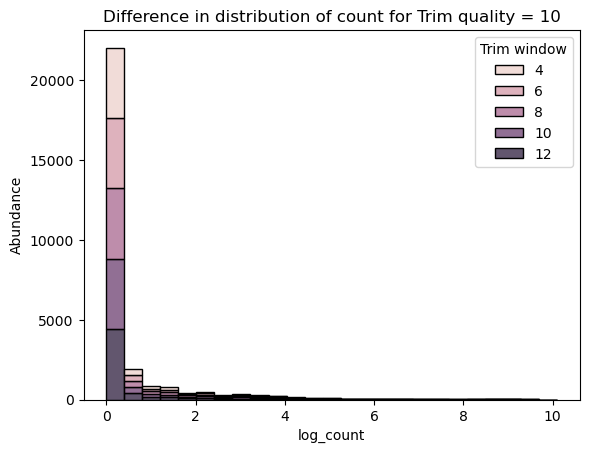

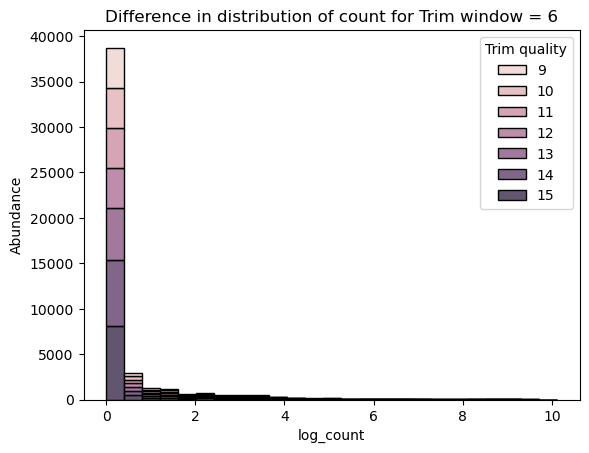

In [10]:
results_df_masked = results_df[(results_df[param_1] == param_1_default_value)].copy()
results_df_masked.loc[:, 'log_count'] = np.log(results_df_masked['count'])

sb.histplot(data=results_df_masked, x='log_count', binwidth=np.log(1.5), hue=param_2, multiple='stack')
plt.title(f'Difference in distribution of count for {param_1} = {param_1_default_value}')
plt.ylabel('Abundance')
plt.show()

results_df_masked = results_df[(results_df[param_2] == param_2_default_value)].copy()
results_df_masked.loc[:, 'log_count'] = np.log(results_df_masked['count'])

sb.histplot(data=results_df_masked, x='log_count', binwidth=np.log(1.5), hue=param_1, multiple='stack')
plt.title(f'Difference in distribution of count for {param_2} = {param_2_default_value}')
plt.ylabel('Abundance')
plt.show()

The heatmap shows the singleton entry proportion (the number of lines where count=1 divided by the total count) based on the combo of parameters.

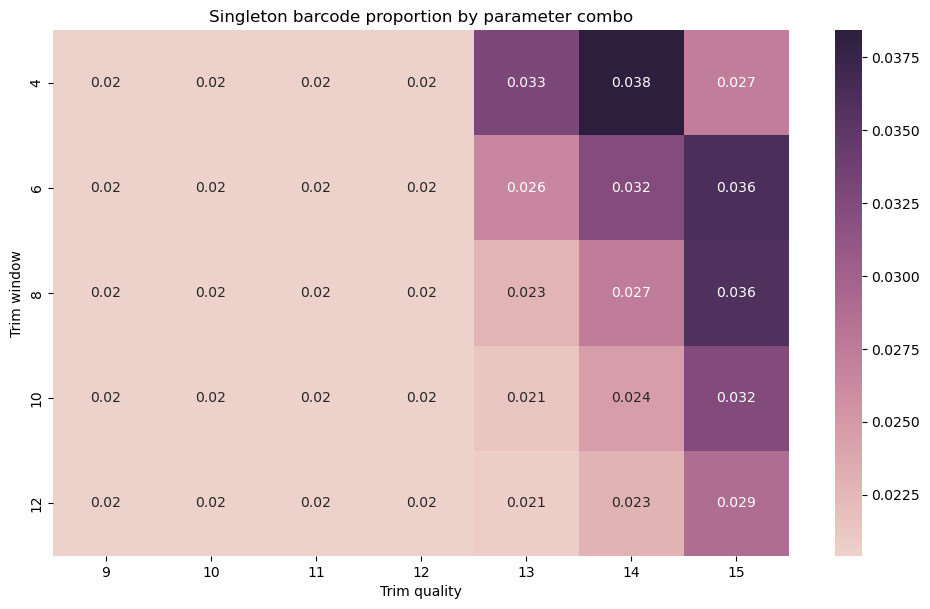

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))

pivot_data = info_df.pivot(index=param_2, columns=param_1, values="singleton_entry_proportion")
sb.heatmap(pivot_data, annot=True, square=True, cmap=sb.cubehelix_palette(as_cmap=True), ax=ax,)

plt.title('Singleton barcode proportion by parameter combo')

# Show the plot
plt.tight_layout()  # Prevent label cutoff
plt.show()

We can visualize both singleton entries and pearson skew with a scatterplot. Blue dots show the singleton entry proportion, and red dots show the pearson skew.

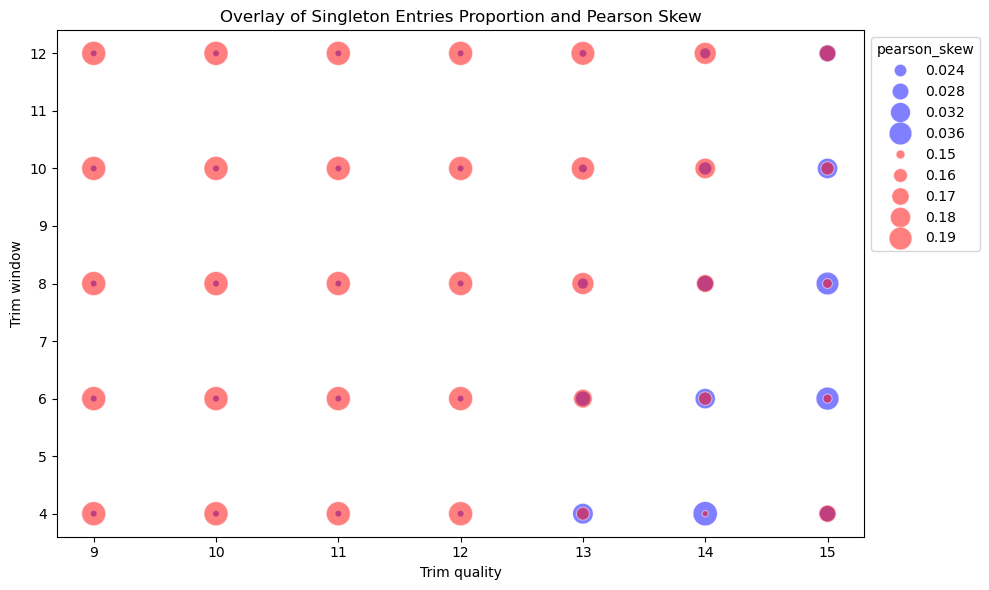

In [21]:
fig, ax = plt.subplots(figsize=(10, 6))

# First scatterplot (singleton_entry_proportion)
scatter1 = sb.scatterplot(
    data=info_df,
    x=param_1,
    y=param_2,
    size='singleton_entry_proportion',
    sizes=(20, 300),
    alpha=0.5,
    color='blue',  # Different color for distinction
    ax=ax
)

# Second scatterplot (pearson_skew) - overlayed on the same axis
scatter2 = sb.scatterplot(
    data=info_df,
    x=param_1,
    y=param_2,
    size='pearson_skew',
    sizes=(20, 300),
    alpha=0.5,
    color='red',  # Different color for distinction
    ax=ax
)

# Customize legends to avoid overlap
sb.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

# Add title and labels
plt.title('Overlay of Singleton Entries Proportion and Pearson Skew')
plt.xlabel(param_1)
plt.ylabel(param_2)

# Show the plot
plt.tight_layout()  # Prevent label cutoff
plt.show()
plt.show()

This code generates a unique color for a given barcode. 

In [22]:
import hashlib
import colorsys

def barcode_to_color(input_string, saturation=0.8, value=0.9):
    # Create a hash of the string to get a consistent numeric value
    hash_int = hash(input_string)
    
    # We'll use the hue component for maximum distinguishability
    hue = (hash_int % 360) / 360.0  # Normalize to 0-1
    
    # Convert HSV to RGB
    color = colorsys.hsv_to_rgb(hue,saturation,value)
    r, g, b = color
    
    # Convert to 0-255 range and hex format
    r = int(r * 255)
    g = int(g * 255)
    b = int(b * 255)

    return "#{:02x}{:02x}{:02x}".format(r, g, b)

The following function plots event (barcode) proportions as a function of a given variable parameter.

In [23]:
def plot_event_proportions(data_masked, variable_param, fish, top_n=20, figsize=(12, 7)):
    # Create pivot table and fill NaN with 0
    pivot_df = data_masked.pivot(index=variable_param, columns='event', values='proportion').fillna(0)
    
    # Calculate mean proportion and sort
    event_means = pivot_df.mean().sort_values(ascending=False)
    top_events = event_means.head(top_n).index
    other_events = event_means[top_n:].index
    
    # Create new dataframe with top events (sorted) + "Other"
    plot_df = pivot_df[top_events].copy()
    plot_df['Other'] = pivot_df[other_events].sum(axis=1)
    
    # Reverse column order to put most abundant on top
    plot_df = plot_df[list(top_events)[::-1] + ['Other']]
    
    # Create a color array based on unique barcodes
    colors = []
    for barcode in top_events:
        colors.insert(0, barcode_to_color(barcode))
    colors.append((0.9, 0.9, 0.9))  # Light gray for "Other"
    
    # Create plot
    plt.figure(figsize=figsize)
    stacks = plt.stackplot(plot_df.index, plot_df.values.T,
                          colors=colors,
                          alpha=0.8)
    
    # Create custom legend with only "Other"
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=colors[-1], label='Other ({} events)'.format(len(other_events)))]
    plt.legend(handles=legend_elements, loc='upper right')

    plt.title(f'Event Proportions by {variable_param} in {fish}\n(Top {top_n} individual events + others grouped)',
             fontsize=14)
    plt.xlabel(variable_param, fontsize=12)
    plt.ylabel('Proportion', fontsize=12)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

The following function plots event counts as a function of a given variable parameter, displaying the data in a different way.

In [24]:
def plot_array_counts(data_masked, variable_param, fish, top_n=20, figsize=(12, 7)):
    # Get variable values in sorted order
    variable_values = data_masked[variable_param].value_counts().sort_values().index
    fig, ax = plt.subplots(figsize=figsize)

    # Create a dataframe for each variable value
    data_dfs = []
    for value in variable_values:
        data_dfs.append(data_masked[data_masked[variable_param] == value].sort_values(by='proportion', ascending=False).head(top_n))

    # Create scaterplot for each dataframe
    for data in data_dfs:
        # Create a color column based on unique barcodes
        data['color'] = data['event'].apply(lambda x: barcode_to_color(x))
        data['log_count'] = data['count'].apply(np.log)
        sb.scatterplot(data=data,
                       x='array',
                       y='count',
                       hue='event',
                       alpha=0.5,
                       palette=data['color'].to_list(), 
                       ax=ax, 
                       legend=False, 
                       s=300)

    # Create a lineplot connecting the points of each scatterplot
    all_data = pd.concat(data_dfs)
    sb.lineplot(data=all_data, x='array', y='count', hue=variable_param, legend=True)
    plt.title(f'Event Counts by {variable_param} in {fish}\n(Top {top_n} individual events)', fontsize=14)
    plt.ylabel('Count')
    plt.xlabel('Event index')
    plt.xticks(np.arange(0, 20, 2))
    # Show the plots
    plt.show()

The color of the dots in the scatterplots are the same colors as the stacked lineplots (the same color represents the same barcode)

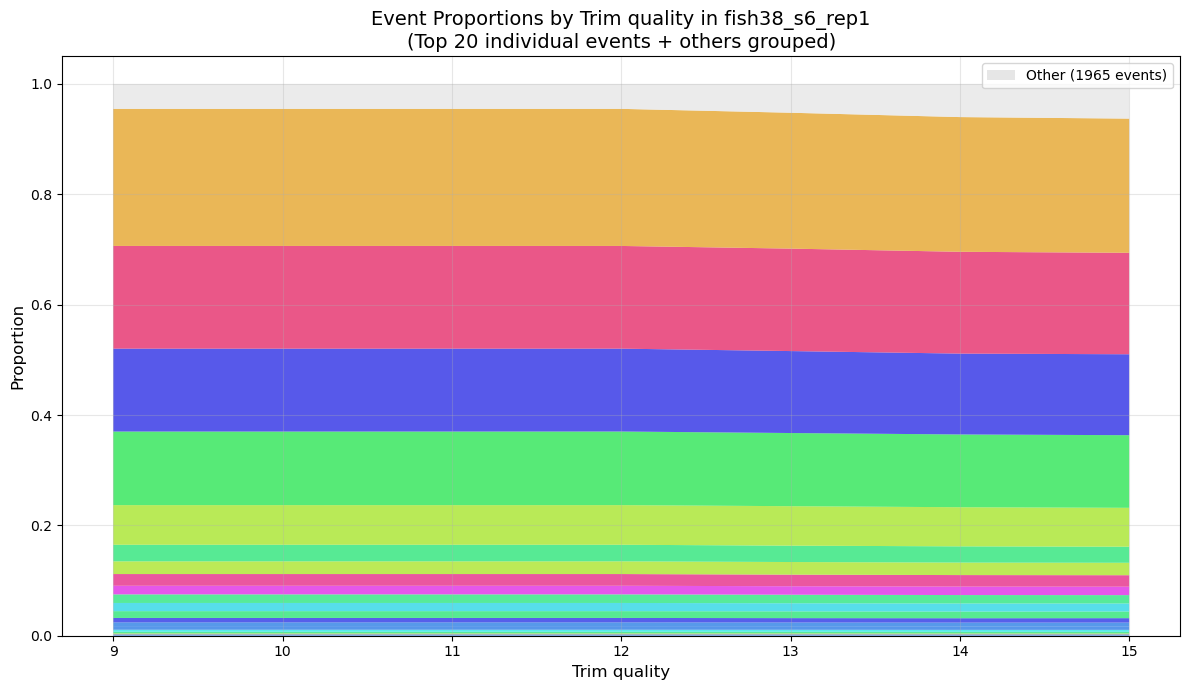

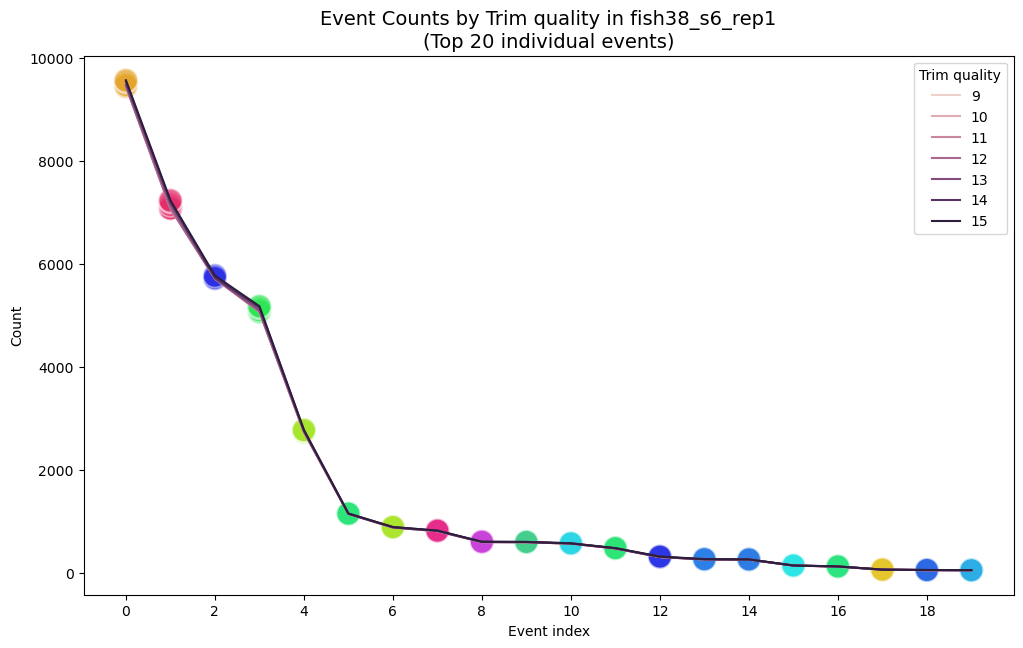

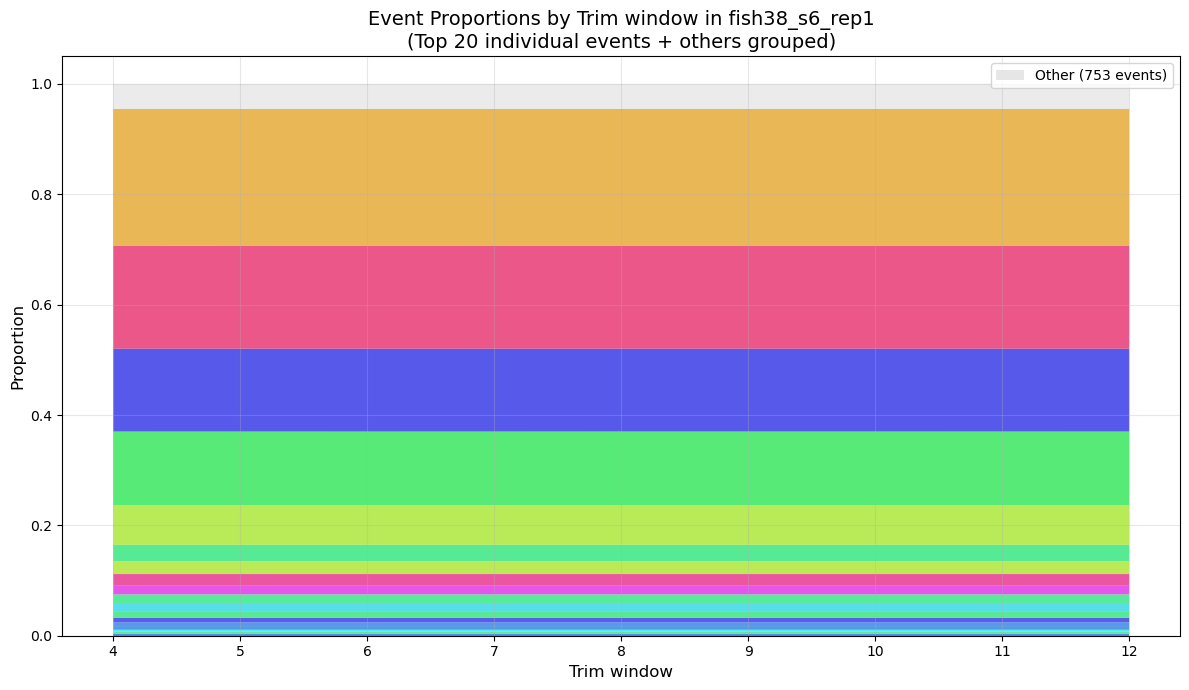

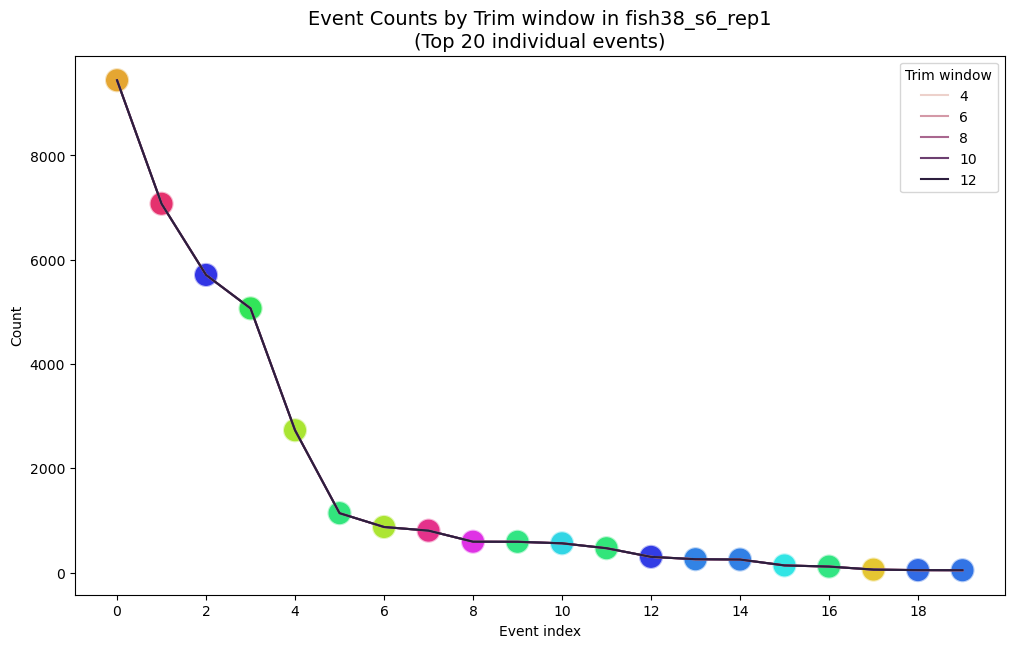

In [25]:
def mask_constant_param_and_fish(data: pd.DataFrame, fish: str, variable_param: str, const_param: str, const_value):
    return data[(data['Fish'] == fish) & (data[const_param] == const_value)]

# Change this to the fish you want to plot
fish = 'fish38_s6_rep1'

# Plot for param 1:
plot_event_proportions(
    mask_constant_param_and_fish(
        data=results_df,
        fish=fish,
        variable_param=param_1,
        const_param=param_2,
        const_value = param_2_default_value),
    param_1,
    fish,
    top_n=20)

plot_array_counts(
    mask_constant_param_and_fish(
        data=results_df,
        fish=fish,
        variable_param=param_1,
        const_param=param_2,
        const_value = param_2_default_value), 
    param_1,
    fish)

# Plot for param 2:
plot_event_proportions(
    mask_constant_param_and_fish(
        data=results_df,
        fish=fish,
        variable_param=param_2,
        const_param=param_1,
        const_value = param_1_default_value),
    param_2,
    fish,
    top_n=20)

plot_array_counts(
    mask_constant_param_and_fish(
        data=results_df,
        fish=fish,
        variable_param=param_2,
        const_param=param_1,
        const_value = param_1_default_value), 
    param_2,
    fish)